# Workshop 3 — MDP Formulation
## Real Estate Investment Decision-Making

**Course:** Machine Learning — Semester 2026-III
**Team:** Group 1 — Housing Price Prediction

This notebook specifies the Markov Decision Process (MDP) underlying our
reinforcement learning formulation for real estate investment. It connects
the theoretical formulation (see `report/mdp_formulation.pdf`) with the
actual code implementation in `src/env.py`.

## 1. Problem Statement

The agent acts as a real estate investor who decides month by month whether
to **wait**, **buy**, **renovate**, or **sell** a property to maximize
cumulative net profit over a 10-year horizon under stochastic market dynamics.

In [1]:
import sys
sys.path.append("../src")

import numpy as np
import matplotlib.pyplot as plt

from env import RealEstateInvestmentEnv
from utils import load_config, set_seed

set_seed(42)
config = load_config("../configs/default.yaml")
print("Configuration loaded.")

Configuration loaded.


## 2. MDP Tuple

The MDP is defined by the tuple **(S, A, P, R, γ, T)**:

| Component | Specification |
|-----------|---------------|
| S | ℝ⁸ — 8 normalized continuous features |
| A | Discrete(4) — WAIT, BUY, RENOVATE, SELL |
| P | s_{t+1} = f(s_t, a_t, ε_t); price follows geometric random walk |
| R | Dense per-step + terminal reward |
| γ | 0.99 |
| T | 120 months |

## 3. State Space

| # | Feature | Range |
|---|---------|-------|
| 1 | Current price | [0, 1] |
| 2 | Market average price | [0, 1] |
| 3 | Price trend (3m) | [0, 1] |
| 4 | Ownership flag | {0, 1} |
| 5 | Property condition | [0, 1] |
| 6 | Available capital | [0, 1] |
| 7 | Months held | [0, 1] |
| 8 | Time step | [0, 1] |

In [2]:
env = RealEstateInvestmentEnv(config)
print("Action space:", env.action_space)
print("Observation space:", env.observation_space)

obs, info = env.reset(seed=42)
print("Initial observation:", obs)
print("Initial info:", info)

Action space: Discrete(4)
Observation space: Box(0.0, 1.0, (8,), float32)
Initial observation: [0.5547912 0.5547912 0.5       0.        0.5755514 0.5       0.
 0.       ]
Initial info: {'t': 0, 'price': 1.1095824194223853, 'capital': 1.0, 'owns': 0, 'condition': 0.575551375900821}


## 4. Action Set

| Index | Action | Valid when |
|-------|--------|------------|
| 0 | WAIT | Always |
| 1 | BUY | Not owning |
| 2 | RENOVATE | Owning |
| 3 | SELL | Owning |

In [3]:
for a in range(4):
    print(f"Action {a} valid: {env._is_valid_action(a)}")

Action 0 valid: True
Action 1 valid: True
Action 2 valid: False
Action 3 valid: False


## 5. Transition Dynamics (sample trajectory)

Random walk simulation of the price process over 120 months.

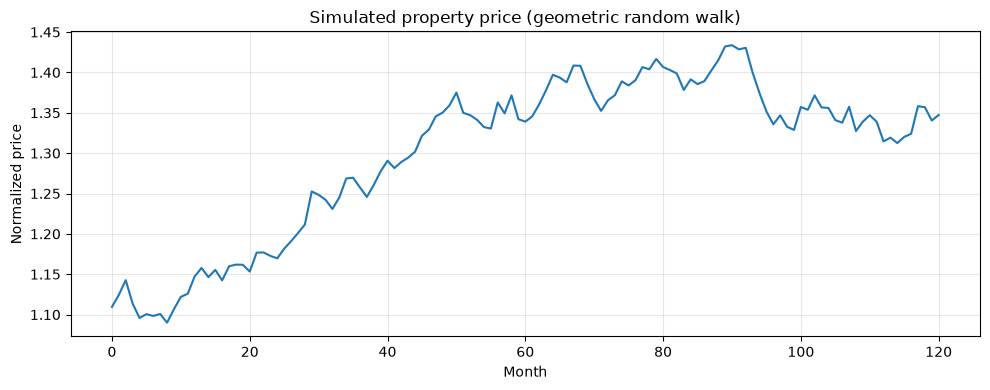

In [4]:
env.reset(seed=42)
prices = [env._state["price"]]
for _ in range(120):
    env._update_price()
    prices.append(env._state["price"])

plt.figure(figsize=(10, 4))
plt.plot(prices)
plt.title("Simulated property price (geometric random walk)")
plt.xlabel("Month")
plt.ylabel("Normalized price")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../results/figures/price_process.png", dpi=150)
plt.show()

## 6. Reward Function

Dense per-step rewards + terminal forced-sale penalty. See Section 6 of
`report/mdp_formulation.pdf` for the full specification.

In [5]:
print("Reward parameters:")
print(f"  Buying cost rate:      {env.buying_cost_rate}")
print(f"  Selling cost rate:     {env.selling_cost_rate}")
print(f"  Renovation cost:       {env.renovation_cost}")
print(f"  Maintenance monthly:   {env.maintenance_cost}")
print(f"  Invalid action penalty:{env.invalid_action_penalty}")
print(f"  Idle capital penalty:  {env.idle_capital_penalty}")

Reward parameters:
  Buying cost rate:      0.03
  Selling cost rate:     0.05
  Renovation cost:       0.08
  Maintenance monthly:   0.002
  Invalid action penalty:0.05
  Idle capital penalty:  0.001


## 7. Episode Termination

An episode ends when:
1. Horizon T = 120 months is reached.
2. Capital falls below bankruptcy threshold.
3. (Evaluation only) Capital exceeds success threshold.

In [6]:
obs, _ = env.reset(seed=42)
done = False
steps = 0
while not done:
    action = env.action_space.sample()
    obs, reward, terminated, truncated, info = env.step(action)
    done = terminated or truncated
    steps += 1

print(f"Episode ended after {steps} steps")
print(f"Terminated (bankruptcy/success): {terminated}")
print(f"Truncated (horizon): {truncated}")
print(f"Final capital: {info['capital']:.3f}")

Episode ended after 120 steps
Terminated (bankruptcy/success): False
Truncated (horizon): True
Final capital: 0.974


## 8. Summary

This notebook formalized the MDP and validated that the environment
implements it correctly. The next notebook (`02_env_validation.ipynb`)
will run 100 random-policy episodes to verify diagnostics, as required
by the workshop.